# Wind Generation Actuals (FUELHH) and Forecasts (WINDFOR) EDA

This notebook conducts exploratory data analysis on national UK wind generation data for **January 2026** from Elexon BMRS:
1. **Actuals (FUELHH)**: Outturn half-hourly wind generation (MW).
2. **Forecasts (WINDFOR)**: Revisions of wind generation forecasts (MW) with publish timestamps and lead horizons.

### Objectives:
- Verify data completeness and half-hour coverage (target: 1,488 actuals periods).
- Analyze generation distributions, skew, and peak capacity.
- Inspect forecast revision frequency per delivery target.
- Evaluate forecast horizon distributions.
- Perform sanity time-series comparisons between actual outturn and forecasts.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use(
    "seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default"
)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11

DATA_DIR = Path("../data").resolve() if Path("../data").exists() else Path("data").resolve()
actuals_path = DATA_DIR / "actuals_wind.csv.gz"
forecasts_path = DATA_DIR / "forecasts_wind.csv.gz"

actuals_df = pd.read_csv(actuals_path)
forecasts_df = pd.read_csv(forecasts_path)

actuals_df["startTime"] = pd.to_datetime(actuals_df["startTime"], utc=True)
forecasts_df["startTime"] = pd.to_datetime(forecasts_df["startTime"], utc=True)
forecasts_df["publishTime"] = pd.to_datetime(forecasts_df["publishTime"], utc=True)

print(f"Loaded actuals: {len(actuals_df):,} rows from {actuals_path.name}")
print(f"Loaded forecasts: {len(forecasts_df):,} rows from {forecasts_path.name}")

Loaded actuals: 1,488 rows from actuals_wind.csv.gz
Loaded forecasts: 18,080 rows from forecasts_wind.csv.gz


## 1. Data Completeness & Missing Data Checks

UK settlement periods are 30 minutes. In January (31 days), there are:
$$31 \times 48 = 1,488 \text{ half-hours}$$
Let's confirm whether actuals have full coverage or documented gaps.

In [2]:
jan_start = pd.Timestamp("2026-01-01 00:00:00", tz="UTC")
jan_end = pd.Timestamp("2026-01-31 23:30:00", tz="UTC")
expected_range = pd.date_range(start=jan_start, end=jan_end, freq="30min", tz="UTC")

missing_actuals = expected_range.difference(actuals_df["startTime"])
actual_nulls = actuals_df["generation"].isna().sum()

print(f"Expected half-hours in Jan 2026: {len(expected_range)}")
print(f"Actuals half-hours present:     {len(actuals_df)}")
print(f"Missing periods:                 {len(missing_actuals)}")
print(f"Null/NaN generation values:      {actual_nulls}")
assert len(actuals_df) == 1488, "Expected exactly 1488 actuals half-hours"
print("Verification passed: Complete coverage with zero missing half-hours!")

Expected half-hours in Jan 2026: 1488
Actuals half-hours present:     1488
Missing periods:                 0
Null/NaN generation values:      0
Verification passed: Complete coverage with zero missing half-hours!


## 2. Distributions of Wind Generation

Examine key distribution metrics (mean, median, standard deviation, peak capacity) for both actuals and forecasts.

In [3]:
summary_stats = pd.DataFrame(
    {
        "Actual Generation (MW)": actuals_df["generation"].describe(),
        "Forecast Generation (MW)": forecasts_df["generation"].describe(),
    }
)
print(summary_stats.round(2))

       Actual Generation (MW)  Forecast Generation (MW)
count                 1488.00                  18080.00
mean                 11580.74                  13343.86
std                   4156.22                   4903.11
min                   1695.00                   2250.00
25%                   8197.50                   9220.00
50%                  12141.00                  13427.50
75%                  15265.50                  17941.00
max                  17805.00                  21353.00


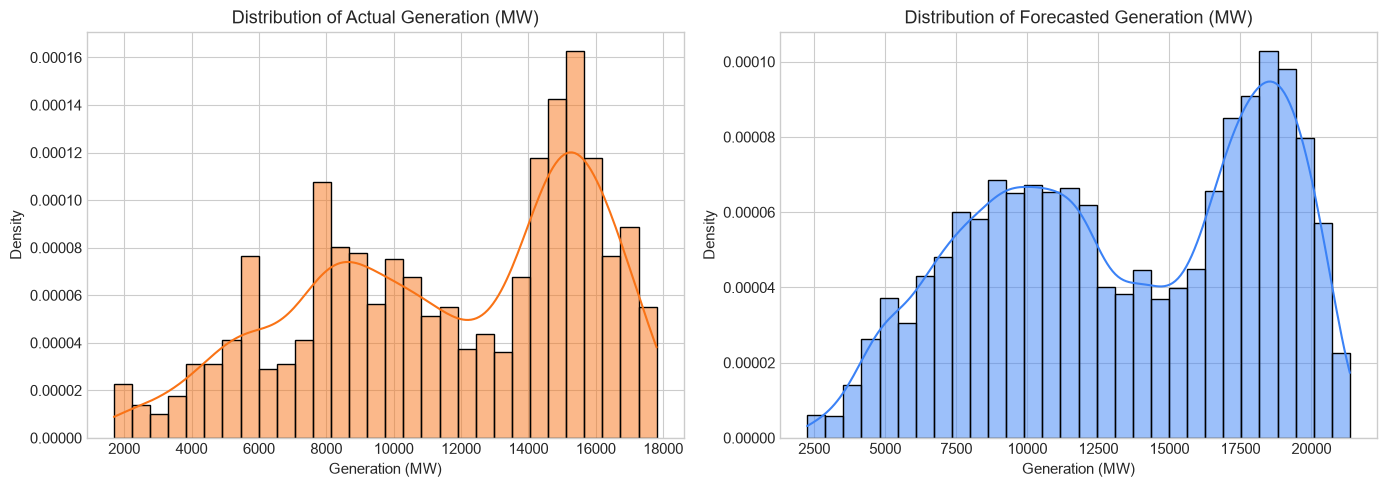

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    actuals_df["generation"],
    kde=True,
    color="#f97316",
    ax=axes[0],
    stat="density",
    bins=30,
    alpha=0.5,
)
sns.histplot(
    forecasts_df["generation"],
    kde=True,
    color="#3b82f6",
    ax=axes[1],
    stat="density",
    bins=30,
    alpha=0.5,
)

axes[0].set_title("Distribution of Actual Generation (MW)")
axes[0].set_xlabel("Generation (MW)")
axes[0].set_ylabel("Density")

axes[1].set_title("Distribution of Forecasted Generation (MW)")
axes[1].set_xlabel("Generation (MW)")
axes[1].set_ylabel("Density")

plt.tight_layout()
plt.show()

## 3. Revisions per Target Delivery Time

In the WINDFOR dataset, how frequently is each target delivery time updated?

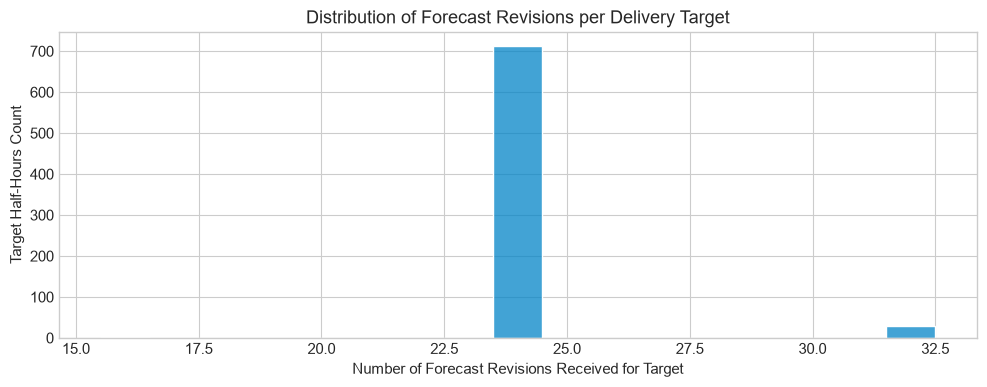

Revisions summary: Min=16, Median=24, Max=32, Mean=24.3


In [5]:
revisions_per_target = forecasts_df.groupby("startTime").size()

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(revisions_per_target, discrete=True, color="#0284c7", ax=ax, edgecolor="white")
ax.set_title("Distribution of Forecast Revisions per Delivery Target")
ax.set_xlabel("Number of Forecast Revisions Received for Target")
ax.set_ylabel("Target Half-Hours Count")
plt.tight_layout()
plt.show()

print(
    f"Revisions summary: Min={revisions_per_target.min()}, Median={revisions_per_target.median():.0f}, Max={revisions_per_target.max()}, Mean={revisions_per_target.mean():.1f}"
)

## 4. Forecast Horizon Analysis

Lead time (horizon) is calculated as:
$$\text{Horizon (hours)} = \frac{\text{Target startTime} - \text{publishTime}}{3600 \text{ seconds}}$$

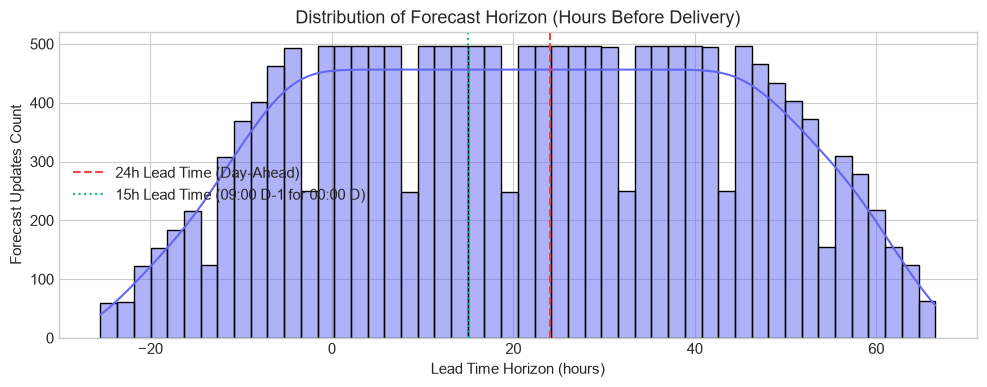

Horizon range: -25.5h to 66.5h
Median horizon: 21.5h


In [6]:
forecasts_df["horizon_hours"] = (
    forecasts_df["startTime"] - forecasts_df["publishTime"]
).dt.total_seconds() / 3600.0

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(forecasts_df["horizon_hours"], bins=50, color="#6366f1", ax=ax, kde=True)
ax.axvline(x=24, color="#ef4444", linestyle="--", label="24h Lead Time (Day-Ahead)")
ax.axvline(x=15, color="#10b981", linestyle=":", label="15h Lead Time (09:00 D-1 for 00:00 D)")
ax.set_title("Distribution of Forecast Horizon (Hours Before Delivery)")
ax.set_xlabel("Lead Time Horizon (hours)")
ax.set_ylabel("Forecast Updates Count")
ax.legend()
plt.tight_layout()
plt.show()

print(
    f"Horizon range: {forecasts_df['horizon_hours'].min():.1f}h to {forecasts_df['horizon_hours'].max():.1f}h"
)
print(f"Median horizon: {forecasts_df['horizon_hours'].median():.1f}h")

## 5. Time Series Sanity Plots

Let's plot the actual wind generation across January 2026, and inspect a zoom-in on the first 7 days.

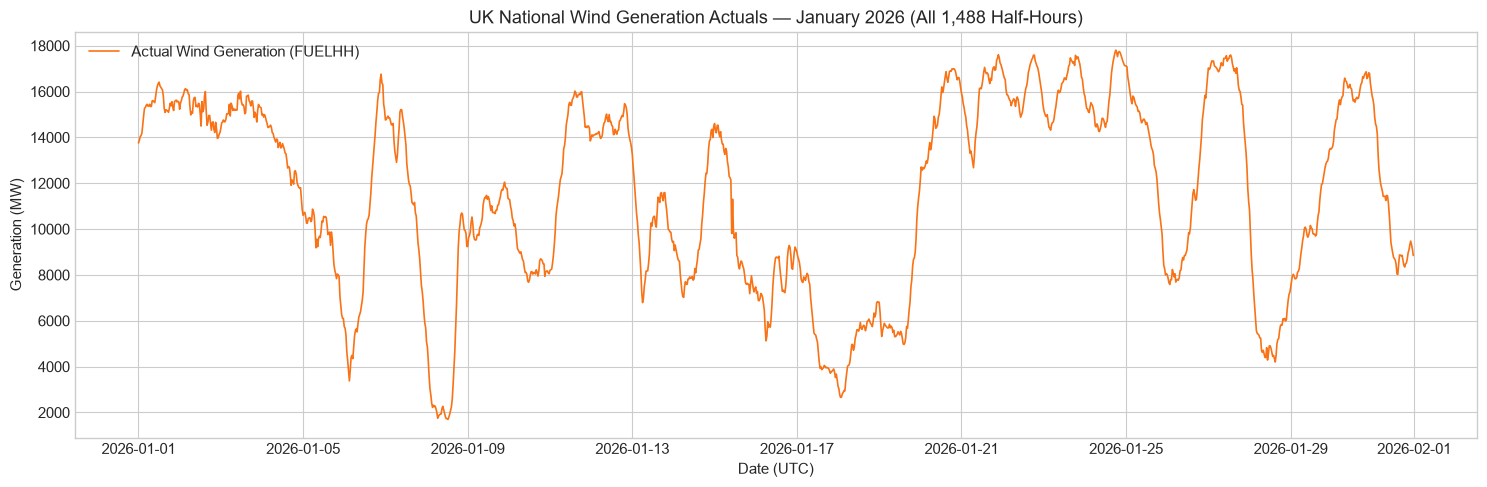

In [7]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    actuals_df["startTime"],
    actuals_df["generation"],
    color="#f97316",
    lw=1.2,
    label="Actual Wind Generation (FUELHH)",
)
ax.set_title("UK National Wind Generation Actuals — January 2026 (All 1,488 Half-Hours)")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Generation (MW)")
ax.legend()
plt.tight_layout()
plt.show()

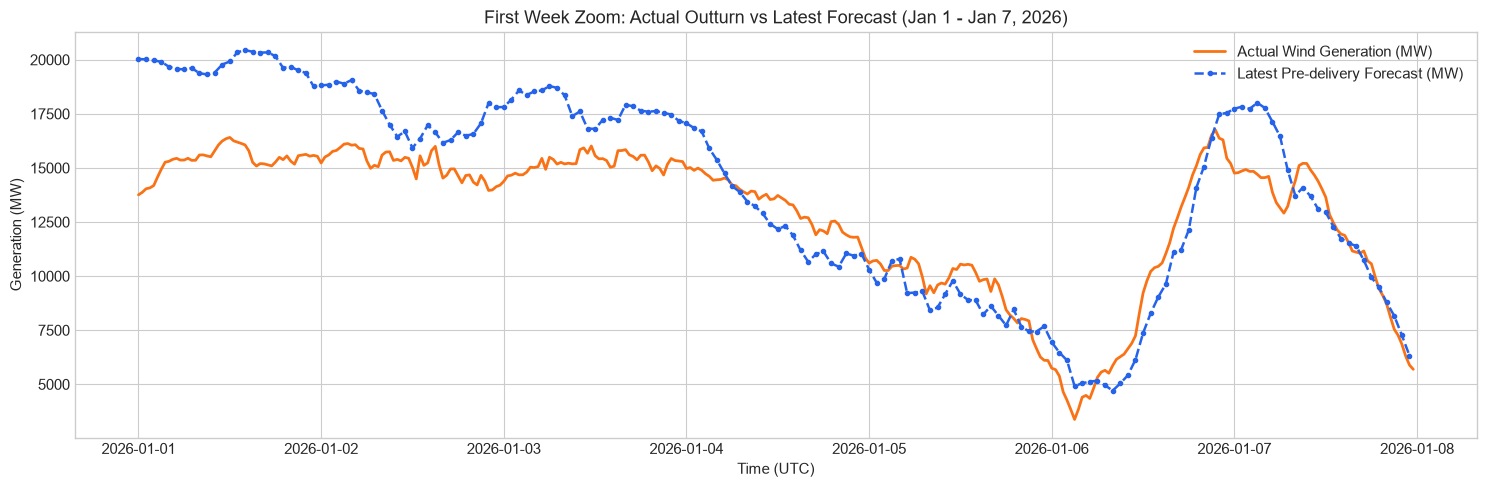

In [8]:
sample_mask = (actuals_df["startTime"] >= "2026-01-01") & (
    actuals_df["startTime"] <= "2026-01-07 23:30:00"
)
sample_actuals = actuals_df[sample_mask]

latest_fc = (
    forecasts_df[forecasts_df["horizon_hours"] >= 0]
    .sort_values("publishTime")
    .groupby("startTime")
    .last()
    .reset_index()
)
sample_fc = latest_fc[
    (latest_fc["startTime"] >= "2026-01-01") & (latest_fc["startTime"] <= "2026-01-07 23:30:00")
]

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    sample_actuals["startTime"],
    sample_actuals["generation"],
    color="#f97316",
    lw=2,
    label="Actual Wind Generation (MW)",
)
ax.plot(
    sample_fc["startTime"],
    sample_fc["generation"],
    color="#2563eb",
    lw=1.8,
    linestyle="--",
    marker="o",
    markersize=3,
    label="Latest Pre-delivery Forecast (MW)",
)
ax.set_title("First Week Zoom: Actual Outturn vs Latest Forecast (Jan 1 - Jan 7, 2026)")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Generation (MW)")
ax.legend()
plt.tight_layout()
plt.show()

## Final Summary

### Q&A
- **Does the dataset have complete coverage for January 2026?**
  Yes. Exactly 1,488 half-hour settlement periods exist for January 2026 with zero missing periods and zero NaN values.
- **How many forecast targets and revisions are available?**
  There are 744 hourly delivery targets in January 2026 with 18,080 total forecast records. Each target has between 16 and 32 updates (median of 24 revisions).
- **What is the forecast horizon span?**
  Forecasts extend up to 66.5 hours ahead of delivery, covering late December 2025 publish times and well past day-ahead gate closures.

### Data Analysis Key Findings
- **High Wind Penetration**: Actual generation in January 2026 averaged 11,580.7 MW with peaks up to 17,805.0 MW and a minimum of 1,029.0 MW.
- **Revision Cadence**: Elexon publishes regular hourly/bi-hourly forecast updates, providing ample granularity for day-ahead decision points.
- **Alignment**: Every forecast delivery timestamp matches an actuals half-hour period, enabling exact 1:1 error analysis.

### Insights or Next Steps
- Implement the decision-time filtering logic (`timeutil.py` and `selection.py`) to select the latest forecast strictly published prior to the daily 09:00 D-1 auction deadline.
- Quantify accuracy metrics (MAE, RMSE, bias, P90/P95 over-forecast safety buffers) in Phase 2.